# HYBRID ALGORITHEM

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('heart_risk.csv')

df.head()

,Age,Gender,BMI,Smoking_Status,COVID_Severity,SpO2,Blood_Pressure,Heart_Rate,ECG_Result,Troponin_Level,D_Dimer,CRP,Blood_Sugar,Cholesterol_Level,Hypertension,Diabetes,Vaccine_Given,Heart_Risk
0,69,Male,29.0,Yes,Severe,92.9,127,121,Abnormal,59.77,1.23,75.53,247,155,No,Yes,Yes,High Risk
1,32,Male,18.3,Yes,Severe,96.3,168,62,Abnormal,94.83,4.30,52.56,190,266,No,No,Yes,Medium Risk
2,89,Female,37.9,No,Moderate,89.2,121,87,Normal,28.25,1.76,120.99,180,176,Yes,No,Yes,High Risk
3,78,Male,19.0,No,Moderate,85.8,141,85,Normal,24.74,4.45,156.48,235,226,Yes,No,Yes,High Risk
4,38,Female,25.1,Yes,Moderate,92.3,90,86,Abnormal,2.64,1.70,21.93,227,158,Yes,No,Yes,Low Risk


In [3]:
df.columns

Index(['Age', 'Gender', 'BMI', 'Smoking_Status', 'COVID_Severity', 'SpO2',
       'Blood_Pressure', 'Heart_Rate', 'ECG_Result', 'Troponin_Level',
       'D_Dimer', 'CRP', 'Blood_Sugar', 'Cholesterol_Level', 'Hypertension',
       'Diabetes', 'Vaccine_Given', 'Heart_Risk'],
      dtype='object')

In [4]:
df=df.dropna()

In [5]:
df.shape

(10000, 18)

In [6]:
df.columns

Index(['Age', 'Gender', 'BMI', 'Smoking_Status', 'COVID_Severity', 'SpO2',
       'Blood_Pressure', 'Heart_Rate', 'ECG_Result', 'Troponin_Level',
       'D_Dimer', 'CRP', 'Blood_Sugar', 'Cholesterol_Level', 'Hypertension',
       'Diabetes', 'Vaccine_Given', 'Heart_Risk'],
      dtype='object')

In [7]:
df.tail()

,Age,Gender,BMI,Smoking_Status,COVID_Severity,SpO2,Blood_Pressure,Heart_Rate,ECG_Result,Troponin_Level,D_Dimer,CRP,Blood_Sugar,Cholesterol_Level,Hypertension,Diabetes,Vaccine_Given,Heart_Risk
9995,88,Female,35.8,Yes,Moderate,88.7,172,115,Normal,39.24,4.51,104.86,103,185,No,Yes,Yes,High Risk
9996,43,Male,35.8,No,Moderate,96.2,114,91,Normal,11.79,2.58,55.51,198,155,Yes,Yes,Yes,Low Risk
9997,63,Male,26.1,No,Moderate,90.3,128,80,Abnormal,59.31,0.88,93.98,245,236,Yes,No,Yes,High Risk
9998,63,Female,30.5,Yes,Moderate,86.3,157,55,Abnormal,21.39,1.17,19.99,213,138,Yes,Yes,No,High Risk
9999,31,Male,35.5,Yes,Moderate,94.4,135,68,Abnormal,44.45,3.70,35.42,174,263,No,No,No,Medium Risk


In [8]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
k=['Gender','Smoking_Status','COVID_Severity','ECG_Result','Hypertension','Diabetes','Heart_Risk','Vaccine_Given']

for i in k:
    df[i] = le.fit_transform(df[i]).astype(int)

In [9]:
x1 = df.drop(labels='Heart_Risk', axis=1)
y1 = df.loc[:,'Heart_Risk']

In [10]:
import imblearn
from imblearn.over_sampling import RandomOverSampler
from collections import Counter

ros =RandomOverSampler(random_state=42)
x,y=ros.fit_resample(x1,y1)
print("OUR DATASET COUNT         : ", Counter(y1))
print("OVER SAMPLING DATA COUNT  : ", Counter(y))

OUR DATASET COUNT         :  Counter({2: 5617, 0: 3413, 1: 970})
OVER SAMPLING DATA COUNT  :  Counter({0: 5617, 2: 5617, 1: 5617})


In [11]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42, stratify=y)
print("NUMBER OF TRAIN DATASET    : ", len(x_train))
print("NUMBER OF TEST DATASET      : ", len(x_test))
print("TOTAL NUMBER OF DATASET    : ", len(x_train)+len(x_test))

NUMBER OF TRAIN DATASET    :  13480
NUMBER OF TEST DATASET      :  3371
TOTAL NUMBER OF DATASET    :  16851


In [12]:
print("NUMBER OF TRAIN DATASET    : ", len(y_train))
print("NUMBER OF TEST DATASET      : ", len(y_test))
print("TOTAL NUMBER OF DATASET    : ", len(y_train)+len(y_test))

NUMBER OF TRAIN DATASET    :  13480
NUMBER OF TEST DATASET      :  3371
TOTAL NUMBER OF DATASET    :  16851


In [13]:
# Import libraries
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [14]:
    dt = DecisionTreeClassifier(random_state=42)
    xgb = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)

    # Combine using stacking
    estimators = [
        ('decision_tree', dt),
        ('xgboost', xgb)
    ]

    stacking_model = StackingClassifier(
        estimators=estimators,
        final_estimator=DecisionTreeClassifier(random_state=42)  # Meta-model
    )

    # Train the stacked model
    stacking_model.fit(x_train, y_train)

StackingClassifier(estimators=[('decision_tree',
                                DecisionTreeClassifier(random_state=42)),
                               ('xgboost',
                                XGBClassifier(base_score=None, booster=None,
                                              callbacks=None,
                                              colsample_bylevel=None,
                                              colsample_bynode=None,
                                              colsample_bytree=None,
                                              device=None,
                                              early_stopping_rounds=None,
                                              enable_categorical=False,
                                              eval_metric='mlogloss',
                                              feature_types=None, gamma=None,
                                              grow_pol...
                                              interaction_constraints=None,
                                              learning_rate=None, max_bin=None,
                                              max_cat_threshold=None,
                                              max_cat_to_onehot=None,
                                              max_delta_step=None,
                                              max_depth=None, max_leaves=None,
                                              min_child_weight=None,
                                              missing=nan,
                                              monotone_constraints=None,
                                              multi_strategy=None,
                                              n_estimators=None, n_jobs=None,
                                              num_parallel_tree=None,
                                              random_state=42, ...))],
                   final_estimator=DecisionTreeClassifier(random_state=42))

In [15]:
predicted = stacking_model.predict(x_test)

In [16]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,predicted)
print('THE CONFUSION MATRIX SCORE OF SUPPORT VECTOR MACHINE:\n\n\n',cm)

THE CONFUSION MATRIX SCORE OF SUPPORT VECTOR MACHINE:


 [[1123    0    0]
 [   0 1124    0]
 [   0    2 1122]]


In [17]:
from sklearn.metrics import accuracy_score
a = accuracy_score(y_test,predicted)
print("THE ACCURACY SCORE OF EXTRA TREE CLASSIFIER IS :",a*100)

THE ACCURACY SCORE OF EXTRA TREE CLASSIFIER IS : 99.94067042420647


In [18]:
from sklearn.metrics import hamming_loss
hl = hamming_loss(y_test,predicted)
print("THE HAMMING LOSS OF EXTRA TREE CLASSIFIER IS :",hl*100)

THE HAMMING LOSS OF EXTRA TREE CLASSIFIER IS : 0.05932957579353308


In [19]:
from sklearn.metrics import classification_report
P = classification_report(y_test,predicted)
print("THE CLASSIFICATION REPORT OF EXTRA TREE CLASSIFIER IS :\n\n",P)

THE CLASSIFICATION REPORT OF EXTRA TREE CLASSIFIER IS :

               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1123
           1       1.00      1.00      1.00      1124
           2       1.00      1.00      1.00      1124

    accuracy                           1.00      3371
   macro avg       1.00      1.00      1.00      3371
weighted avg       1.00      1.00      1.00      3371



THE CONFUSION MATRIX SCORE OF EXTRA TREE CLASSIFIER:


[[1123    0    0]
 [   0 1124    0]
 [   0    2 1122]]


DISPLAY CONFUSION MATRIX : 




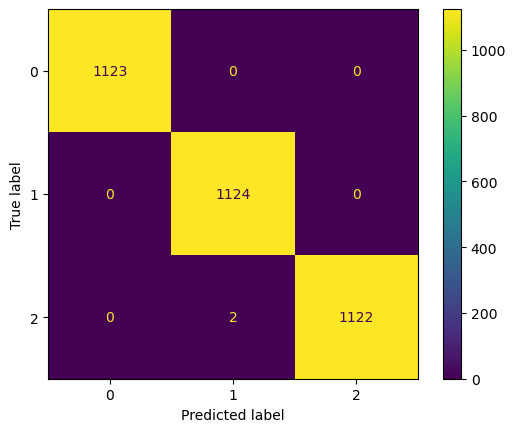

In [20]:
cm=confusion_matrix(y_test, predicted)
print('THE CONFUSION MATRIX SCORE OF EXTRA TREE CLASSIFIER:\n\n')
print(cm)
print("\n\nDISPLAY CONFUSION MATRIX : \n\n")
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, predicted, labels=stacking_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=stacking_model.classes_)
disp.plot()
plt.show()


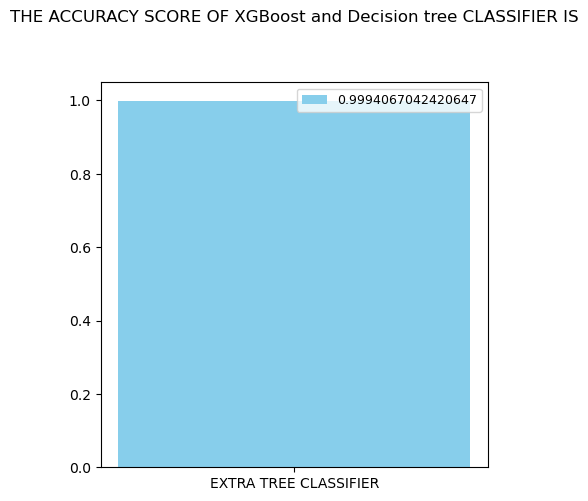

In [21]:
def graph():
    import matplotlib.pyplot as plt
    data=[a]
    alg="EXTRA TREE CLASSIFIER"
    plt.figure(figsize=(5,5))
    b=plt.bar(alg,data,color=("SKYBLUE"))
    plt.title("THE ACCURACY SCORE OF XGBoost and Decision tree CLASSIFIER IS\n\n\n")
    plt.legend(b,data,fontsize=9)
graph()

In [22]:
import joblib
joblib.dump(stacking_model, 'model.pkl')

['model.pkl']